# FINAL TERM REQUIREMENT

## A. DATA UNDERSTANDING AND PREPARATION

### DATA LOADING

In [50]:
import pandas as pd

# Load both datasets
math = pd.read_csv("Datasets/Maths.csv")
portuguese = pd.read_csv("Datasets/Portuguese.csv")

# Combine into one dataset
students = pd.concat([math, portuguese], ignore_index=True)

# Display dataset info
print("Total records:", students.shape)
students.info()

Total records: (1048, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048 entries, 0 to 1047
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      1048 non-null   object
 1   sex         1048 non-null   object
 2   age         1048 non-null   int64 
 3   address     1048 non-null   object
 4   famsize     1048 non-null   object
 5   Pstatus     1048 non-null   object
 6   Medu        1048 non-null   int64 
 7   Fedu        1048 non-null   int64 
 8   Mjob        1048 non-null   object
 9   Fjob        1048 non-null   object
 10  reason      1048 non-null   object
 11  guardian    1048 non-null   object
 12  traveltime  1048 non-null   int64 
 13  studytime   1048 non-null   int64 
 14  failures    1048 non-null   int64 
 15  schoolsup   1048 non-null   object
 16  famsup      1048 non-null   object
 17  paid        1048 non-null   object
 18  activities  1048 non-null   object
 19  nursery     1048 non-n

### EXPLORATORY DATA ANALYSIS (EDA)

#### (a) Distribution of Final Grades

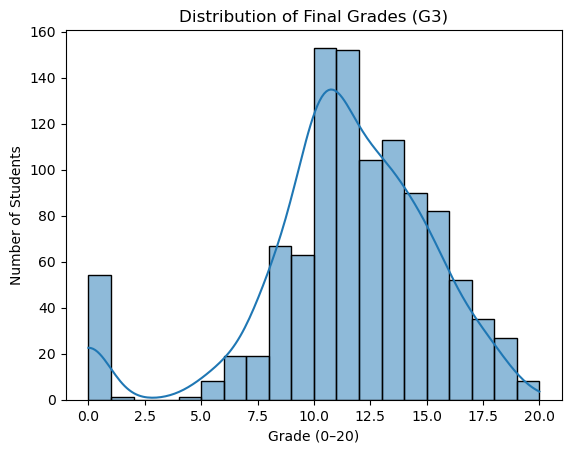

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(students['G3'], bins=20, kde=True)
plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Grade (0–20)")
plt.ylabel("Number of Students")
plt.show()

#### (b) Study Time vs Final Grade

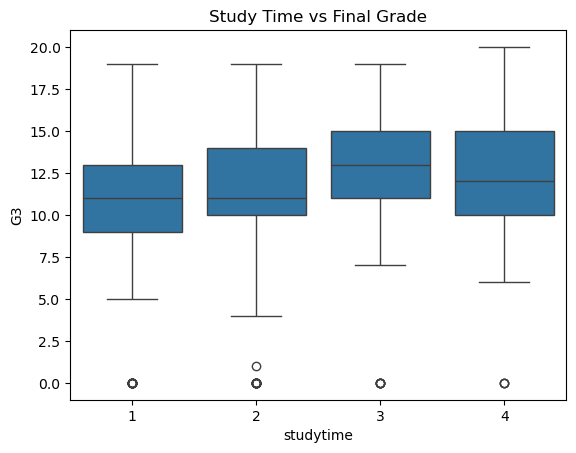

In [57]:
sns.boxplot(x='studytime', y='G3', data=students)
plt.title("Study Time vs Final Grade")
plt.show()

#### (c) Correlation Heatmap

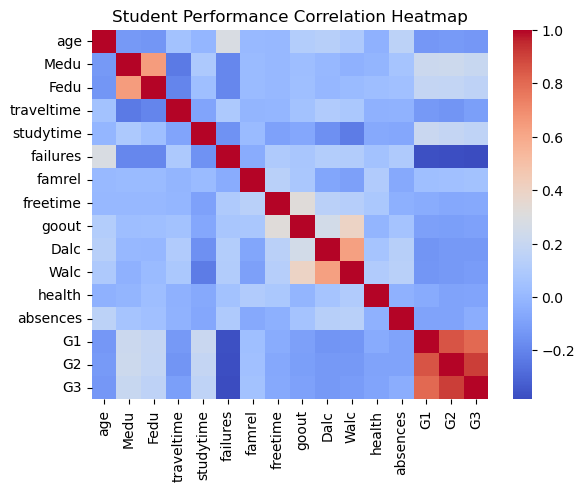

In [60]:
sns.heatmap(students.corr(numeric_only=True), annot=False, cmap='coolwarm')
plt.title("Student Performance Correlation Heatmap")
plt.show()

### DATA PREPROCESSING

#### (a) Handling Missing Values

In [64]:
students.isnull().sum().sum()

0

#### (b) Encoding Categorical Variables

In [ ]:
import pandas as pd
from feature_schema import CATEGORICAL_FEATURES, PREDICTOR_FEATURES

# Keep the source columns intact for analysis. The shared model schema excludes school.
print(f"Model predictors: {len(PREDICTOR_FEATURES)}")
print("Excluded from training: school")


#### (c) Feature Scaling / Normalization

In [ ]:
from feature_schema import PREDICTOR_FEATURES

# G3 is the grade target; school is not part of the predictor frame.
X_students = students[PREDICTOR_FEATURES].copy()
y_students = students['G3'].astype(float)


#### (d) Train–Test Split

In [ ]:
from sklearn.model_selection import train_test_split

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_students, y_students, test_size=0.2, random_state=42
)

print("Train size:", Xs_train.shape)
print("Test size:", Xs_test.shape)


## B. MODEL IMPLEMENTAION

### 1. Initialize Grade Regression Pipeline

In [ ]:
from train_models import build_model

grade_model = build_model()
print("Random Forest grade regression pipeline initialized.")


### 2. Train and Evaluate the Deployment Model

In [ ]:
from train_models import train_and_save

# This evaluates a held-out split, then fits the deployable model on all rows.
training_metrics = train_and_save()


### 3. Review Held-Out Metrics

In [ ]:
results_df = pd.DataFrame([{
    "Model": "Random Forest grade regression",
    "MAE (grade points)": training_metrics["mae"],
    "RMSE (grade points)": training_metrics["rmse"],
    "R²": training_metrics["r2"],
    "Pass/fail accuracy": training_metrics["pass_fail_accuracy"],
}])
results_df


## C. MODEL EVALUATION

### 1. Held-Out Model Evaluation

In [ ]:
print("Target: G3 final grade on a 0–20 scale")
print("Pass/fail rule: predicted grade >= 10 is PASS; below 10 is FAIL")
print("School is excluded from all model predictors.")
results_df


### 2. Visualize the Grade and Pass/Fail Metrics

#### Held-Out Model Performance

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(results_df["Model"], results_df["MAE (grade points)"], color="#89a95a")
axes[0].set_title("Held-out grade error")
axes[0].set_ylabel("Mean absolute error (points)")
axes[0].tick_params(axis="x", rotation=15)
axes[1].bar(results_df["Model"], results_df["Pass/fail accuracy"], color="#e58770")
axes[1].set_title("Held-out pass/fail accuracy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


## D. MODEL RESULTS AND INTERPRETATION

## D. MODEL RESULTS AND INTERPRETATION

The deployed model is a Random Forest regressor trained to estimate the actual final grade (`G3`). It uses the combined Mathematics and Portuguese student datasets. The original `school` column is intentionally excluded from the model predictors.

The model's held-out error and pass/fail accuracy are calculated by `train_models.py` from a separate 20% split. PASS means a predicted final grade of 10/20 or higher. These estimates are for early academic support and should not be treated as a final assessment.


<h2>E. MODEL DEPLOYMENT</h2>

In [ ]:
from pathlib import Path

model_path = Path("models/grade_model.pkl")
if not model_path.exists():
    raise FileNotFoundError("Run the model training cell before checking the deployment artifact.")
print(f"Current school-excluded grade model: {model_path}")
